# Supermarket Sales Analysis
**Data Analytics Project**

**Problem statement:** Analyse supermarket sales data to find useful information about products, branches, categories, customers, payments and ratings, and turn the findings into business decisions.

**Dataset:** 500 sales transactions (`SUPER_MARKET_DATA.xlsx`, sheet `supermarket_sales_500_rows`) — [Google Sheet source](https://docs.google.com/spreadsheets/d/1QIX__4VObHFMEXnRM2xJyXmB5JAB2peHrJcQ41_U9TE/edit?usp=sharing)

**Workflow:** Load → Check data quality → Validate Sales = Quantity × Unit Price → Group & summarise → Visualise → Business decisions

## 1. Import libraries and settings

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
PALETTE = "viridis"
os.makedirs("charts", exist_ok=True)   # charts are saved here for the project report

def rupee(x, _=None):
    return f"₹{x:,.0f}"


## 2. Load the dataset

In [2]:
DATA_FILE = "SUPER_MARKET_DATA.xlsx"
df = pd.read_excel(DATA_FILE, sheet_name="supermarket_sales_500_rows")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (500, 13)


,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


## 3. Understand the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice ID     500 non-null    str           
 1   Date           500 non-null    datetime64[us]
 2   Branch         500 non-null    str           
 3   City           500 non-null    str           
 4   Customer Type  500 non-null    str           
 5   Gender         500 non-null    str           
 6   Product        500 non-null    str           
 7   Category       500 non-null    str           
 8   Quantity       500 non-null    int64         
 9   Unit Price     500 non-null    float64       
 10  Payment        500 non-null    str           
 11  Rating         500 non-null    float64       
 12  Sales          500 non-null    float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(8)
memory usage: 50.9 KB


In [4]:
df.describe().round(2)

,Date,Quantity,Unit Price,Rating,Sales
count,500,500.00,500.00,500.00,500.00
mean,2026-04-03 12:25:55.200000,5.54,88.66,3.99,488.82
min,2026-01-01 00:00:00,1.00,27.67,3.00,28.61
25%,2026-02-17 00:00:00,3.00,43.96,3.50,189.21
50%,2026-04-09 00:00:00,5.50,61.88,4.00,335.91
75%,2026-05-17 06:00:00,8.00,128.57,4.50,609.88
max,2026-07-01 00:00:00,10.00,236.71,5.00,2114.82
std,NaN,2.88,57.28,0.57,437.33


In [5]:
for col in ["Branch", "City", "Customer Type", "Gender", "Category", "Payment"]:
    print(f"{col}: {sorted(df[col].unique())}")
print("Products:", df["Product"].nunique())

Branch: ['A', 'B', 'C', 'D']
City: ['Bengaluru', 'Delhi', 'Jaipur', 'Mumbai']
Customer Type: ['Member', 'Normal']
Gender: ['Female', 'Male']
Category: ['Bakery', 'Beverages', 'Dairy', 'Fruits', 'Grocery', 'Personal Care', 'Snacks', 'Vegetables']
Payment: ['Card', 'Cash', 'Net Banking', 'UPI']
Products: 20


## 4. Check for missing or incorrect values
Checks: missing values, duplicate rows/invoices, invalid quantities, prices and ratings, and one-to-one mappings (Branch ↔ City, Product ↔ Category).

In [6]:
print("Missing values per column:")
print(df.isna().sum(), "\n")

print("Duplicate rows          :", df.duplicated().sum())
print("Duplicate Invoice IDs   :", df["Invoice ID"].duplicated().sum())
print("Quantity <= 0           :", (df["Quantity"] <= 0).sum())
print("Unit Price <= 0         :", (df["Unit Price"] <= 0).sum())
print("Rating outside 1-5      :", (~df["Rating"].between(1, 5)).sum())
print("Date range              :", df["Date"].min().date(), "to", df["Date"].max().date())

print("\nBranch -> City mapping (should be one-to-one):")
print(df.groupby("Branch")["City"].unique())
print("\nProducts that appear in more than one category:",
      (df.groupby("Product")["Category"].nunique() > 1).sum())

Missing values per column:
Invoice ID       0
Date             0
Branch           0
City             0
Customer Type    0
Gender           0
Product          0
Category         0
Quantity         0
Unit Price       0
Payment          0
Rating           0
Sales            0
dtype: int64 

Duplicate rows          : 0
Duplicate Invoice IDs   : 0
Quantity <= 0           : 0
Unit Price <= 0         : 0
Rating outside 1-5      : 0
Date range              : 2026-01-01 to 2026-07-01

Branch -> City mapping (should be one-to-one):
Branch
A       [Jaipur]
B        [Delhi]
C       [Mumbai]
D    [Bengaluru]
Name: City, dtype: object

Products that appear in more than one category: 0


**Result:** the dataset is clean — no missing values, no duplicates, valid quantities/prices/ratings, and consistent Branch–City and Product–Category mappings. No rows needed to be removed.

## 5. Calculate Sales = Quantity × Unit Price
The dataset already has a `Sales` column. We recompute it independently and confirm it matches.

In [7]:
df["Sales_Check"] = (df["Quantity"] * df["Unit Price"]).round(2)
mismatch = (df["Sales_Check"] - df["Sales"]).abs().gt(0.01).sum()
print("Rows where recalculated Sales differs from the Sales column:", mismatch)

df["Month"] = df["Date"].dt.to_period("M")
df.drop(columns="Sales_Check", inplace=True)

Rows where recalculated Sales differs from the Sales column: 0


## 6. Overall business summary (KPIs)

In [8]:
total_sales = df["Sales"].sum()
kpis = pd.Series({
    "Total transactions": len(df),
    "Total sales (₹)": round(total_sales, 2),
    "Average transaction value (₹)": round(df["Sales"].mean(), 2),
    "Total units sold": int(df["Quantity"].sum()),
    "Average customer rating (out of 5)": round(df["Rating"].mean(), 2),
})
kpis.to_frame("Value")

,Value
Total transactions,500.00
Total sales (₹),244411.08
Average transaction value (₹),488.82
Total units sold,2768.00
Average customer rating (out of 5),3.99


## 7. Live analysis — answering the business questions

### Q1. Which product generates the highest sales?

Product
Cheese         27906.30
Coffee         27694.87
Shampoo        27497.48
Cooking Oil    21525.06
Tea            17681.59
Apples         17057.41
Face Wash      11946.85
Rice           11754.17
Cold Drink     10731.78
Eggs           10429.77
Name: Sales, dtype: float64


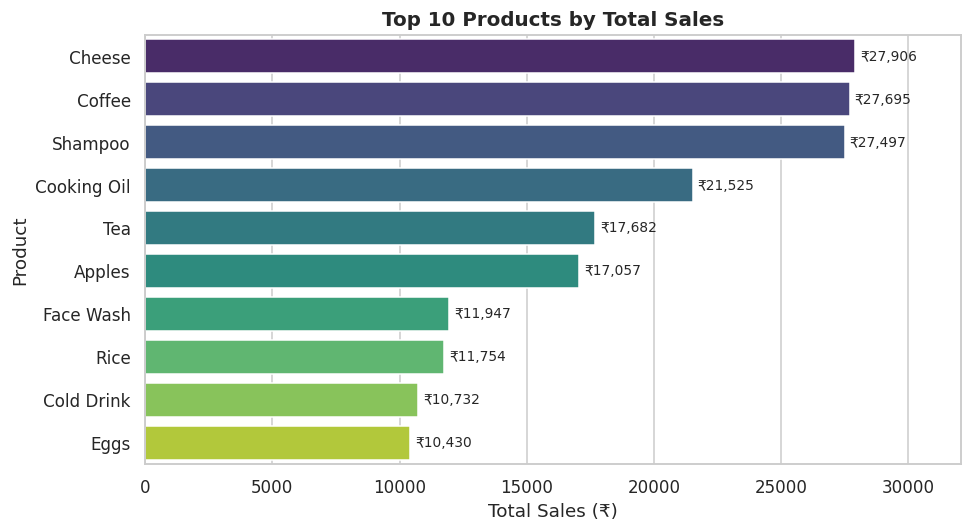


Answer: Cheese generated the highest sales: ₹27,906.30


In [9]:
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)
print(product_sales.head(10).round(2))

top10 = product_sales.head(10)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette=PALETTE, legend=False, ax=ax)
ax.set_title("Top 10 Products by Total Sales")
ax.set_xlabel("Total Sales (₹)"); ax.set_ylabel("Product")
for i, v in enumerate(top10.values):
    ax.text(v + 200, i, rupee(v), va="center", fontsize=9)
ax.set_xlim(0, top10.max() * 1.15)
plt.tight_layout(); plt.savefig("charts/q1_top_products.png"); plt.show()

print(f"\nAnswer: {product_sales.index[0]} generated the highest sales: ₹{product_sales.iloc[0]:,.2f}")

### Q2. Which branch performs best?

,,Total_Sales,Transactions,Avg_Transaction,Avg_Rating
Branch,City,,,,
C,Mumbai,72469.45,143,506.78,4.05
B,Delhi,64116.26,133,482.08,3.98
D,Bengaluru,55468.29,119,466.12,4.09
A,Jaipur,52357.08,105,498.64,3.84


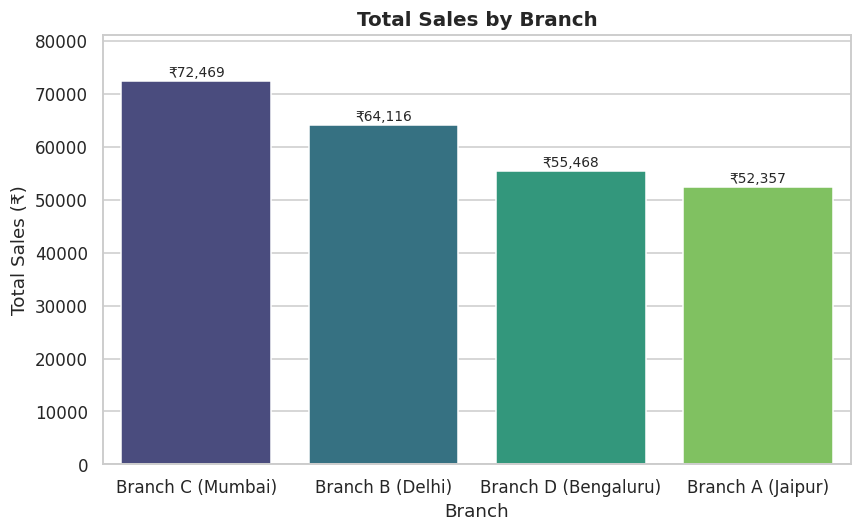

Answer: Branch C (Mumbai) performed best with sales of ₹72,469.45


In [10]:
branch = (df.groupby(["Branch", "City"])
            .agg(Total_Sales=("Sales", "sum"), Transactions=("Invoice ID", "count"),
                 Avg_Transaction=("Sales", "mean"), Avg_Rating=("Rating", "mean"))
            .sort_values("Total_Sales", ascending=False).round(2))
display(branch)

b = branch.reset_index()
b["Label"] = "Branch " + b["Branch"] + " (" + b["City"] + ")"
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=b, x="Label", y="Total_Sales", hue="Label", palette=PALETTE, legend=False, ax=ax)
ax.set_title("Total Sales by Branch"); ax.set_xlabel("Branch"); ax.set_ylabel("Total Sales (₹)")
for i, v in enumerate(b["Total_Sales"]):
    ax.text(i, v + 800, rupee(v), ha="center", fontsize=9)
ax.set_ylim(0, b["Total_Sales"].max() * 1.12)
plt.tight_layout(); plt.savefig("charts/q2_branch_sales.png"); plt.show()

best = b.iloc[0]
print(f"Answer: Branch {best['Branch']} ({best['City']}) performed best with sales of ₹{best['Total_Sales']:,.2f}")

### Q3. Which category sells the most?

,Total_Sales,Transactions,Units,Share_%
Category,,,,
Beverages,56108.24,82,465,23.0
Personal Care,45943.96,73,399,18.8
Dairy,43992.00,68,345,18.0
Grocery,40470.47,82,439,16.6
Fruits,23263.17,44,223,9.5
Snacks,16992.97,75,443,7.0
Vegetables,11124.17,48,290,4.6
Bakery,6516.10,28,164,2.7


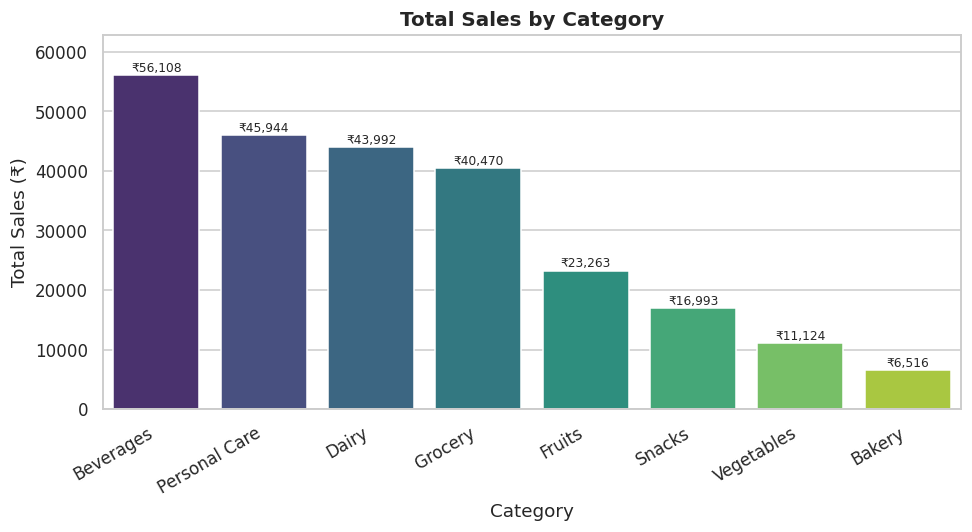

Answer: Beverages had the highest sales with ₹56,108.24


In [11]:
cat = (df.groupby("Category").agg(Total_Sales=("Sales", "sum"), Transactions=("Invoice ID", "count"),
                                   Units=("Quantity", "sum")).sort_values("Total_Sales", ascending=False).round(2))
cat["Share_%"] = (cat["Total_Sales"] / cat["Total_Sales"].sum() * 100).round(1)
display(cat)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=cat.index, y=cat["Total_Sales"], hue=cat.index, palette=PALETTE, legend=False, ax=ax)
ax.set_title("Total Sales by Category"); ax.set_xlabel("Category"); ax.set_ylabel("Total Sales (₹)")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(cat["Total_Sales"]):
    ax.text(i, v + 600, rupee(v), ha="center", fontsize=8)
ax.set_ylim(0, cat["Total_Sales"].max() * 1.12)
plt.tight_layout(); plt.savefig("charts/q3_category_sales.png"); plt.show()

print(f"Answer: {cat.index[0]} had the highest sales with ₹{cat['Total_Sales'].iloc[0]:,.2f}")

### Q4. What is the most popular payment method?

Payment
UPI            127
Net Banking    126
Card           125
Cash           122
Name: count, dtype: int64


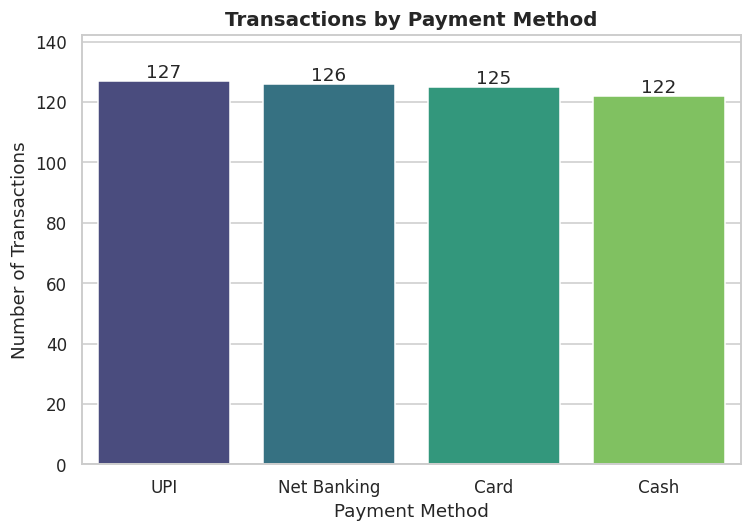

Answer: UPI was the most used payment method with 127 transactions (only 1 more than the runner-up, Net Banking).


In [12]:
pay = df["Payment"].value_counts()
print(pay)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=pay.index, y=pay.values, hue=pay.index, palette=PALETTE, legend=False, ax=ax)
ax.set_title("Transactions by Payment Method"); ax.set_xlabel("Payment Method"); ax.set_ylabel("Number of Transactions")
for i, v in enumerate(pay.values):
    ax.text(i, v + 1, str(v), ha="center")
ax.set_ylim(0, pay.max() * 1.12)
plt.tight_layout(); plt.savefig("charts/q4_payment_methods.png"); plt.show()

print(f"Answer: {pay.index[0]} was the most used payment method with {pay.iloc[0]} transactions "
      f"(only {pay.iloc[0]-pay.iloc[1]} more than the runner-up, {pay.index[1]}).")

### Q5. Do Members spend more than Normal customers?

,Transactions,Total_Sales,Avg_Transaction,Median_Transaction
Customer Type,,,,
Member,296,143009.30,483.14,314.46
Normal,204,101401.78,497.07,352.56


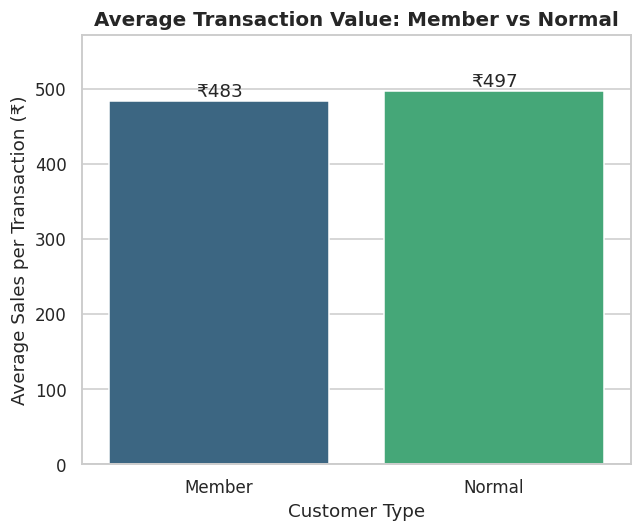

Answer: No. Average Member transaction ₹483.14 vs Normal ₹497.07.


In [13]:
cust = (df.groupby("Customer Type").agg(Transactions=("Invoice ID", "count"), Total_Sales=("Sales", "sum"),
                                         Avg_Transaction=("Sales", "mean"), Median_Transaction=("Sales", "median"))
          .round(2))
display(cust)

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=cust.index, y=cust["Avg_Transaction"], hue=cust.index, palette=PALETTE, legend=False, ax=ax)
ax.set_title("Average Transaction Value: Member vs Normal"); ax.set_xlabel("Customer Type"); ax.set_ylabel("Average Sales per Transaction (₹)")
for i, v in enumerate(cust["Avg_Transaction"]):
    ax.text(i, v + 6, rupee(v), ha="center")
ax.set_ylim(0, cust["Avg_Transaction"].max() * 1.15)
plt.tight_layout(); plt.savefig("charts/q5_customer_type.png"); plt.show()

m, n = cust.loc["Member", "Avg_Transaction"], cust.loc["Normal", "Avg_Transaction"]
print(f"Answer: {'Yes' if m > n else 'No'}. Average Member transaction ₹{m:,.2f} vs Normal ₹{n:,.2f}.")

**Is the Member/Normal gap statistically meaningful?** The gap is only about ₹14. A quick Welch t-test checks whether it could just be random variation (SciPy is optional; this cell is skipped if it is not installed).

In [14]:
try:
    from scipy import stats
    t, p = stats.ttest_ind(df.loc[df["Customer Type"]=="Member", "Sales"],
                           df.loc[df["Customer Type"]=="Normal", "Sales"], equal_var=False)
    print(f"Welch t-test: t = {t:.3f}, p-value = {p:.3f}")
    print("Difference is NOT statistically significant (p > 0.05)." if p > 0.05 else "Difference is statistically significant (p <= 0.05).")
except ImportError:
    print("scipy not installed - skipping the optional significance test.")

Welch t-test: t = -0.346, p-value = 0.730
Difference is NOT statistically significant (p > 0.05).


### Q6. What is the average customer rating?

Answer: The average customer rating was 3.99 out of 5.


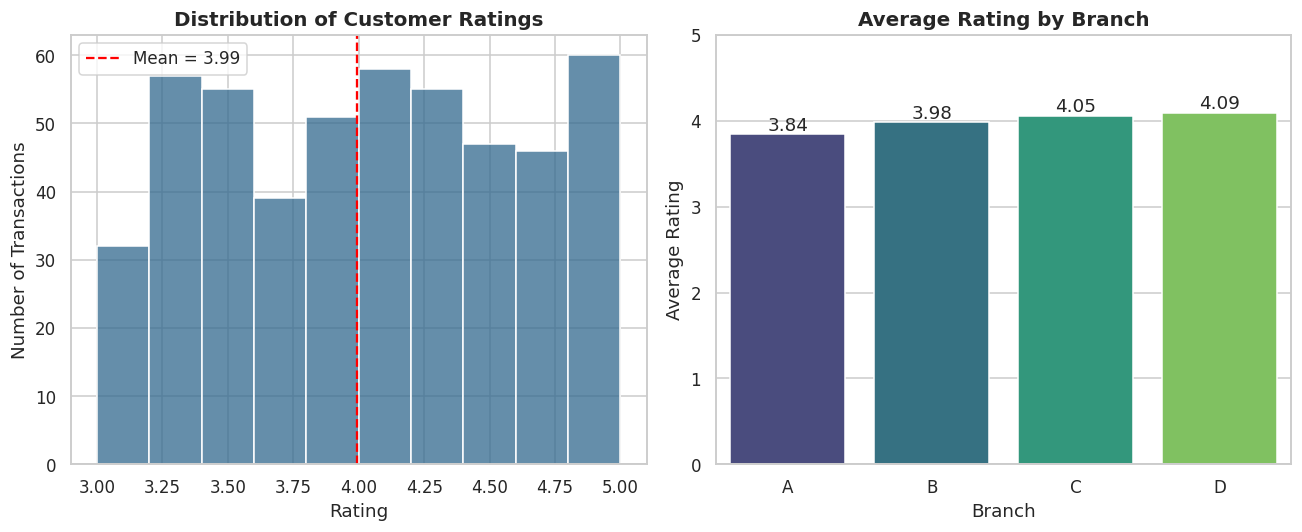

Branch
A    3.84
B    3.98
C    4.05
D    4.09
Name: Rating, dtype: float64


In [15]:
avg_rating = df["Rating"].mean()
print(f"Answer: The average customer rating was {avg_rating:.2f} out of 5.\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["Rating"], bins=10, color="#31688e", ax=axes[0])
axes[0].axvline(avg_rating, color="red", ls="--", label=f"Mean = {avg_rating:.2f}")
axes[0].set_title("Distribution of Customer Ratings"); axes[0].set_xlabel("Rating"); axes[0].set_ylabel("Number of Transactions"); axes[0].legend()

br = df.groupby("Branch")["Rating"].mean().round(2)
sns.barplot(x=br.index, y=br.values, hue=br.index, palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("Average Rating by Branch"); axes[1].set_xlabel("Branch"); axes[1].set_ylabel("Average Rating")
axes[1].set_ylim(0, 5)
for i, v in enumerate(br.values):
    axes[1].text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig("charts/q6_ratings.png"); plt.show()
print(br)

## 8. Additional analysis

### Monthly sales trend

,Sales,Transactions,Days_With_Data
Month,,,
2026-01,43415.53,88,30
2026-02,30068.15,65,28
2026-03,37306.42,83,31
2026-04,52569.77,90,27
2026-05,42542.31,85,29
2026-06,35041.46,82,27
2026-07,3467.44,7,1


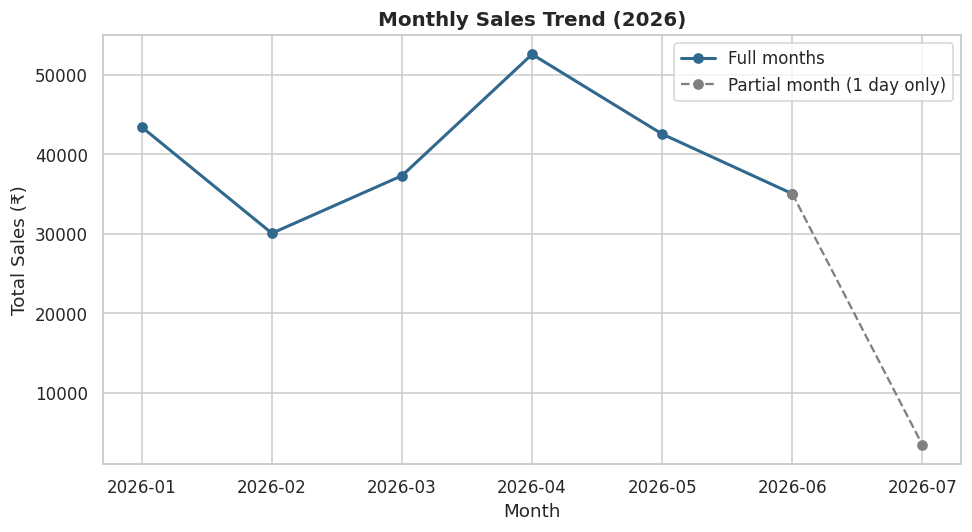

In [16]:
monthly = df.groupby("Month").agg(Sales=("Sales", "sum"), Transactions=("Invoice ID", "count"),
                                   Days_With_Data=("Date", "nunique"))
monthly.index = monthly.index.astype(str)
display(monthly.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(monthly.index[:-1], monthly["Sales"][:-1], marker="o", color="#31688e", lw=2, label="Full months")
ax.plot(monthly.index[-2:], monthly["Sales"][-2:], marker="o", color="grey", ls="--", label="Partial month (1 day only)")
ax.set_title("Monthly Sales Trend (2026)"); ax.set_xlabel("Month"); ax.set_ylabel("Total Sales (₹)")
ax.legend()
plt.tight_layout(); plt.savefig("charts/extra_monthly_trend.png"); plt.show()

> **Note:** July 2026 contains data for **1 day only** (1 July), so its low total is a data-coverage effect and should not be read as a sales decline.

### Category mix by branch

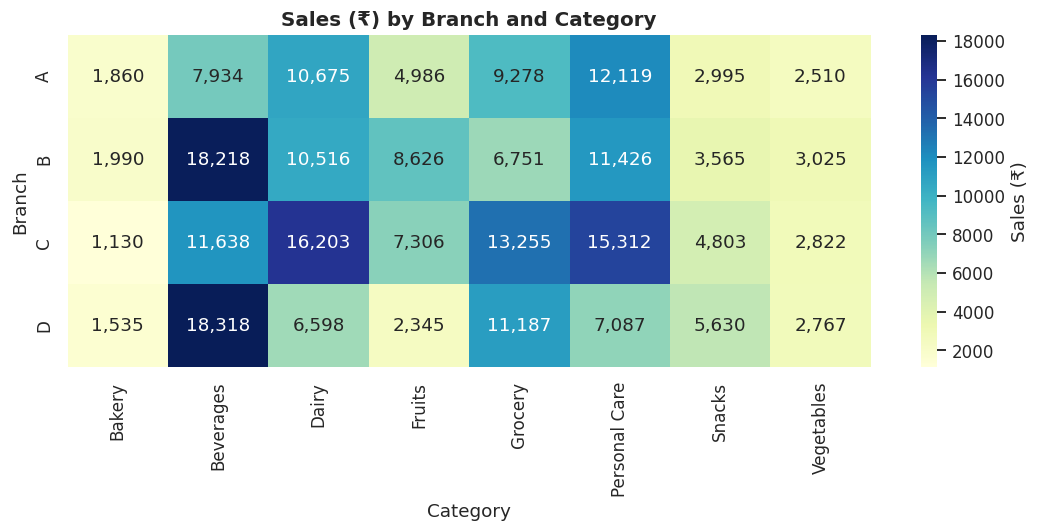

In [17]:
pivot = df.pivot_table(index="Branch", columns="Category", values="Sales", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Sales (₹)"})
ax.set_title("Sales (₹) by Branch and Category")
plt.tight_layout(); plt.savefig("charts/extra_branch_category_heatmap.png"); plt.show()

### Gender and category-level pricing

In [18]:
print(df.groupby("Gender")["Sales"].agg(["count", "sum", "mean"]).round(2), "\n")
print(df.groupby("Category")["Unit Price"].mean().sort_values(ascending=False).round(2))

        count        sum    mean
Gender                          
Female    255  123954.12  486.09
Male      245  120456.96  491.66 

Category
Dairy            128.85
Beverages        118.38
Personal Care    113.86
Fruits            97.12
Grocery           90.74
Bakery            39.90
Vegetables        39.45
Snacks            37.66
Name: Unit Price, dtype: float64


## 9. Key findings

| Question | Answer |
|---|---|
| Highest-selling product | **Cheese** — ₹27,906.30 (Coffee ₹27,694.87 and Shampoo ₹27,497.48 are very close behind) |
| Best branch | **Branch C (Mumbai)** — ₹72,469.45 |
| Top category | **Beverages** — ₹56,108.24 |
| Most popular payment method | **UPI** — 127 transactions (all four methods are within 5 transactions of each other) |
| Do Members spend more? | **No** — Member ₹483.14 vs Normal ₹497.07 per transaction |
| Average rating | **3.99 / 5** |

## 10. Business decisions
1. **Stock priorities:** keep higher stock of Cheese, Coffee, Shampoo and Cooking Oil, and of the Beverages, Personal Care and Dairy categories, which together drive most sales.
2. **Learn from Branch C (Mumbai):** it has the most transactions and the highest average transaction value; study its layout, staffing and promotions and replicate what works at Branch A (Jaipur), the lowest-selling branch.
3. **Keep every payment channel:** UPI leads, but Net Banking, Card and Cash are almost equal, so none can be dropped. Promote UPI cashback to speed up checkout.
4. **Improve service quality:** the average rating is 3.99/5 and Branch A scores lowest (3.84) — targeted service training there can lift ratings.
5. **Rework the membership programme:** Members do not spend more than Normal customers, so offer member-only discounts tied to higher basket sizes (e.g. spend ₹600+) rather than blanket discounts.
6. **Weak categories:** Bakery and Vegetables bring in the least sales; test bundles or promotions before reducing shelf space.

## 11. Conclusion
This analysis turns 500 raw transactions into clear, simple insights that help the supermarket understand performance across products, branches, categories, payments and customers, and make better decisions.